# 프로젝트 : 네이버 영화리뷰 감성분석 도전하기

이전 스텝까지는 영문 텍스트의 감정 분석을 진행해 보았습니다. 그렇다면 이번에는 한국어 텍스트의 감정 분석을 진행해 보면 어떨까요? 오늘 활용할 데이터셋은 네이버 영화의 댓글을 모아 구성된 [Naver sentiment movie corpus](https://github.com/e9t/nsmc)입니다.

아래와 같이 다운로드를 진행해 주세요.



```
$ wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
$ wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt
$ mv ratings_*.txt ~/aiffel/sentiment_classification/data
$ pip install konlpy
$ sudo apt-get install git
$ sudo apt-get install curl
$ bash <(curl -s https://raw.githubusercontent.com/konlpy/konlpy/master/scripts/mecab.sh)

```

프로젝트 진행 순서는 다음과 같습니다.



In [1]:
!wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
!wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt
!mv ratings_*.txt /content/data
!pip install konlpy
!sudo apt-get install git
!sudo apt-get install curl
# !bash <(curl -s https://raw.githubusercontent.com/konlpy/konlpy/master/scripts/mecab.sh)

--2026-11-07 21:57:53--  https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14628807 (14M) [text/plain]
Saving to: ‘ratings_train.txt’

ratings_train.txt   100%[===================>]  13.95M  --.-KB/s    in 0.04s   

2026-11-07 21:57:54 (313 MB/s) - ‘ratings_train.txt’ saved [14628807/14628807]

--2026-11-07 21:57:54--  https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4893335 (4.7M) [application/octet-

In [2]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 115.4 MB/s  0:00:00


## 라이브러리 버전을 확인해 봅니다
---
사용할 라이브러리 버전을 둘러봅시다.

In [3]:
import pandas
import konlpy
import gensim

print(pandas.__version__)
print(konlpy.__version__)
print(gensim.__version__)

2.2.3
0.6.0
4.4.0


## 1) 데이터 준비와 확인
---

In [4]:
import pandas as pd

# 데이터를 읽어봅시다.
train_data = pd.read_table('/content/ratings_train.txt')
test_data = pd.read_table('/content/ratings_test.txt')

train_data.head()

,id,document,label
0,9976970,아 더빙.. 진짜 짜증나네요 목소리,0
1,3819312,흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나,1
2,10265843,너무재밓었다그래서보는것을추천한다,0
3,9045019,교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정,0
4,6483659,사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 ...,1


## 2) 데이터로더 구성
---
실습 때 다루었던 IMDB 데이터셋은 텍스트를 가공하여 `imdb.data_loader()` 메서드를 호출하면 숫자 인덱스로 변환된 텍스트와 `word_to_index` 딕셔너리까지 친절하게 제공합니다. 그러나 이번에 다루게 될 nsmc 데이터셋은 전혀 가공되지 않은 텍스트 파일로 이루어져 있습니다. 이것을 읽어서 `imdb.data_loader()`와 동일하게 동작하는 자신만의 `data_loader`를 만들어 보는 것으로 시작합니다. `data_loader` 안에서는 다음을 수행해야 합니다.

- 데이터의 중복 제거
- NaN 결측치 제거
- 한국어 토크나이저로 토큰화
- 불용어(Stopwords) 제거
- 사전`word_to_index` 구성
- 텍스트 스트링을 사전 인덱스 스트링으로 변환
- `X_train`, `y_train`, `X_test`, `y_test`, `word_to_index` 리턴

In [5]:
## 코랩 Mecab() 설치를 위한 추가 코드_1

!pip install Korpora

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [Korpora]


In [6]:
## 코랩 Mecab() 설치를 위한 추가 코드_2

!git clone https://github.com/SOMJANG/Mecab-ko-for-Google-Colab.git

Cloning into 'Mecab-ko-for-Google-Colab'...
remote: Enumerating objects: 138, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 138 (delta 26), reused 22 (delta 8), pack-reused 91 (from 1)
Receiving objects: 100% (138/138), 1.72 MiB | 15.54 MiB/s, done.
Resolving deltas: 100% (65/65), done.


In [7]:
## 코랩 Mecab() 설치를 위한 추가 코드_3

%cd Mecab-ko-for-Google-Colab/

/content/Mecab-ko-for-Google-Colab


In [8]:
## 코랩 Mecab() 설치를 위한 추가 코드_4

# !bash install_mecab-ko_on_colab_light_220429.sh

In [9]:
%pip install -q python-mecab-ko

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for python-mecab-ko (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for python-mecab-ko
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> python-mecab-ko


In [10]:
from mecab import MeCab
import numpy as np
from collections import Counter

tokenizer = MeCab()
stopwords = ['의','가','이','은','들','는','좀','잘','걍','과','도','를','으로','자','에','와','한','하다']

def load_data(train_data, test_data, num_words=10000):
    train_data.drop_duplicates(subset=['document'], inplace=True)
    train_data = train_data.dropna(how = 'any')
    test_data.drop_duplicates(subset=['document'], inplace=True)
    test_data = test_data.dropna(how = 'any')

    X_train = []
    for sentence in train_data['document']:
        temp_X = tokenizer.morphs(sentence) # 토큰화
        temp_X = [word for word in temp_X if not word in stopwords] # 불용어 제거
        X_train.append(temp_X)

    X_test = []
    for sentence in test_data['document']:
        temp_X = tokenizer.morphs(sentence) # 토큰화
        temp_X = [word for word in temp_X if not word in stopwords] # 불용어 제거
        X_test.append(temp_X)

    words = np.concatenate(X_train).tolist()
    counter = Counter(words)
    counter = counter.most_common(10000-4)
    vocab = ['', '', '', ''] + [key for key, _ in counter]
    word_to_index = {word:index for index, word in enumerate(vocab)}

    def wordlist_to_indexlist(wordlist):
        return [word_to_index[word] if word in word_to_index else word_to_index[''] for word in wordlist]

    X_train = list(map(wordlist_to_indexlist, X_train))
    X_test = list(map(wordlist_to_indexlist, X_test))

    return X_train, np.array(list(train_data['label'])), X_test, np.array(list(test_data['label'])), word_to_index

X_train, y_train, X_test, y_test, word_to_index = load_data(train_data, test_data)

ModuleNotFoundError: No module named 'mecab'

원본 셀의 `python-mecab-ko`는 현재 Colab(Python 3.13)에서 wheel 빌드가 실패했고, 그래서 바로 위 셀의 `from mecab import MeCab`도 `ModuleNotFoundError`가 났다. 지난 단어사전 프로젝트에서 동작했던 KoNLPy + `mecab-ko` + `mecab-python3` 조합으로 설치를 바꿨다.

또 원본 `load_data`는 특수 토큰 자리가 빈 문자열 네 개(`['', '', '', '']`)라서 딕셔너리를 만들면 네 개가 키 하나로 합쳐지고 `''`만 인덱스 3으로 남는다. 이렇게 되면 0번(`<PAD>`)과 1·2번 자리가 비고, 아래 `get_encoded_sentence`처럼 `'<BOS>'`, `'<UNK>'`를 찾는 코드는 KeyError가 난다. 그래서 `<PAD>`, `<BOS>`, `<UNK>`, `<UNUSED>`를 명시해서 다시 작성했다. 단어사전은 train 데이터에서만 만들었다.

In [11]:
%pip install -q konlpy mecab-ko mecab-python3

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [12]:
import os
import importlib
import numpy as np
from collections import Counter
import mecab_ko_dic

os.environ['MECABRC'] = os.path.join(mecab_ko_dic.DICDIR, 'mecabrc')

# 위 6번 셀에서 konlpy를 이미 import한 상태라, 설치 후 Mecab 모듈을 다시 읽어야 Tagger를 찾는다.
import konlpy.tag._mecab as mecab_module
importlib.reload(mecab_module)
tokenizer = mecab_module.Mecab(dicpath=mecab_ko_dic.DICDIR)
print(tokenizer.morphs('이 영화 진짜 재밌었는데 결말이 좀 아쉬웠다'))

stopwords = ['의','가','이','은','들','는','좀','잘','걍','과','도','를','으로','자','에','와','한','하다']

def load_data(train_data, test_data, num_words=10000):
    """중복·결측 제거 → 형태소 토큰화 → 불용어 제거 → train 기준 사전 → 인덱스 변환"""
    train_data = train_data.drop_duplicates(subset=['document']).dropna(how='any')
    test_data = test_data.drop_duplicates(subset=['document']).dropna(how='any')

    def tokenize(sentences):
        result = []
        for sentence in sentences:
            tokens = tokenizer.morphs(sentence)
            result.append([w for w in tokens if w not in stopwords])
        return result

    X_train = tokenize(train_data['document'])
    X_test = tokenize(test_data['document'])

    # 빈도 상위 단어로 사전을 만든다. 앞의 4칸은 특수 토큰 자리
    counter = Counter(w for sentence in X_train for w in sentence)
    vocab = ['<PAD>', '<BOS>', '<UNK>', '<UNUSED>'] + [w for w, _ in counter.most_common(num_words - 4)]
    word_to_index = {word: index for index, word in enumerate(vocab)}

    def wordlist_to_indexlist(wordlist):
        return [word_to_index.get(word, word_to_index['<UNK>']) for word in wordlist]

    X_train = list(map(wordlist_to_indexlist, X_train))
    X_test = list(map(wordlist_to_indexlist, X_test))
    return X_train, np.array(train_data['label']), X_test, np.array(test_data['label']), word_to_index

X_train, y_train, X_test, y_test, word_to_index = load_data(train_data, test_data)
print('train:', len(X_train), '/ test:', len(X_test), '/ vocab:', len(word_to_index))
print('train 긍정 비율: {:.4f}, test 긍정 비율: {:.4f}'.format(y_train.mean(), y_test.mean()))

['이', '영화', '진짜', '재밌', '었', '는데', '결말', '이', '좀', '아쉬웠', '다']
train: 146182 / test: 49157 / vocab: 10000
train 긍정 비율: 0.4983, test 긍정 비율: 0.5027


In [13]:
index_to_word = {index:word for word, index in word_to_index.items()}

In [14]:
# 문장 1개를 활용할 딕셔너리와 함께 주면, 단어 인덱스 리스트 벡터로 변환해 주는 함수입니다.
# 단, 모든 문장은 <BOS>로 시작하는 것으로 합니다.
def get_encoded_sentence(sentence, word_to_index):
    return [word_to_index['<BOS>']]+[word_to_index[word] if word in word_to_index else word_to_index['<UNK>'] for word in sentence.split()]

# 여러 개의 문장 리스트를 한꺼번에 단어 인덱스 리스트 벡터로 encode해 주는 함수입니다.
def get_encoded_sentences(sentences, word_to_index):
    return [get_encoded_sentence(sentence, word_to_index) for sentence in sentences]

# 숫자 벡터로 encode된 문장을 원래대로 decode하는 함수입니다.
def get_decoded_sentence(encoded_sentence, index_to_word):
    return ' '.join(index_to_word[index] if index in index_to_word else '<UNK>' for index in encoded_sentence[1:])  #[1:]를 통해 <BOS>를 제외

# 여러 개의 숫자 벡터로 encode된 문장을 한꺼번에 원래대로 decode하는 함수입니다.
def get_decoded_sentences(encoded_sentences, index_to_word):
    return [get_decoded_sentence(encoded_sentence, index_to_word) for encoded_sentence in encoded_sentences]

## 3) 모델 구성을 위한 데이터 분석 및 가공
---
- 데이터셋 내 문장 길이 분포
- 적절한 최대 문장 길이 지정
- keras.preprocessing.sequence.pad_sequences 을 활용한 패딩 추가

문장길이 평균 :  15.952784884595914
문장길이 최대 :  116
문장길이 표준편차 :  12.816172318652985
pad_sequences maxlen :  41
train 문장 중 maxlen 이하 비율: 0.9343
토큰이 0개인 문장 수: train 3, test 2


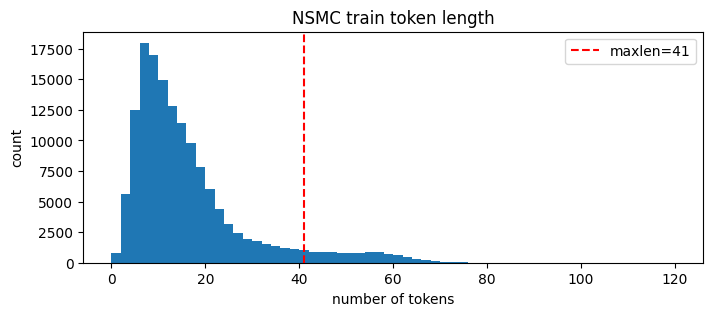

In [15]:
import matplotlib.pyplot as plt

# maxlen은 train 문장 길이로만 정한다 (test 분포를 보고 정하면 test 정보가 새어 들어간다)
lengths = np.array([len(s) for s in X_train])
print('문장길이 평균 : ', np.mean(lengths))
print('문장길이 최대 : ', np.max(lengths))
print('문장길이 표준편차 : ', np.std(lengths))

maxlen = int(np.mean(lengths) + 2 * np.std(lengths))
print('pad_sequences maxlen : ', maxlen)
print('train 문장 중 maxlen 이하 비율: {:.4f}'.format(np.mean(lengths <= maxlen)))
print('토큰이 0개인 문장 수: train {}, test {}'.format(np.sum(lengths == 0), sum(len(s) == 0 for s in X_test)))

plt.figure(figsize=(8, 3))
plt.hist(lengths, bins=60, range=(0, 120))
plt.axvline(maxlen, color='red', linestyle='--', label=f'maxlen={maxlen}')
plt.xlabel('number of tokens')
plt.ylabel('count')
plt.title('NSMC train token length')
plt.legend()
plt.show()

train 문장은 평균 약 16토큰, 최대 116토큰이고 대부분 30토큰 아래에 몰려 있다. 노드 실습처럼 평균 + 2×표준편차로 maxlen을 정하니 41이 나왔고, train 문장의 93.4%가 이 길이 안에 들어간다. 나머지 6.6%는 41토큰 뒤가 잘리지만 분포의 긴 꼬리 부분이라 이 정도면 충분하다고 판단했다.

형태소 분석 후 불용어를 빼면 토큰이 하나도 남지 않는 문장이 train 3개, test 2개 있었다. 이 문장들은 <PAD>만 들어간 입력이 된다.

In [16]:
import torch

def pad_sequences(sequences, maxlen, padding='pre'):
    """길이를 maxlen으로 맞춘다. 긴 문장은 앞 maxlen개만 남기고, 짧은 문장은 padding 방향에 0(<PAD>)을 채운다."""
    padded = np.zeros((len(sequences), maxlen), dtype=np.int64)
    for i, seq in enumerate(sequences):
        seq = seq[:maxlen]
        if len(seq) == 0:
            continue
        if padding == 'pre':
            padded[i, -len(seq):] = seq
        else:
            padded[i, :len(seq)] = seq
    return torch.tensor(padded)

X_train_pre = pad_sequences(X_train, maxlen, 'pre')
X_test_pre = pad_sequences(X_test, maxlen, 'pre')
print(X_train_pre.shape, X_test_pre.shape)
print(X_train_pre[0])
print(get_decoded_sentence([1] + X_train[0], index_to_word))

torch.Size([146182, 41]) torch.Size([49157, 41])
tensor([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,  32, 604,   4,   4,  39, 229,  20,  33, 742])
아 더빙 . . 진짜 짜증 나 네요 목소리


## 4) 모델 구성 및 validation set 구성
---
모델은 3가지 이상 다양하게 구성하여 실험해 보세요.

In [17]:
import random
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
from gensim.models import KeyedVectors

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

# validation은 train에서 10%를 라벨 비율을 유지해서 떼어낸다. test는 마지막 평가에만 쓴다.
idx_tr, idx_val = train_test_split(np.arange(len(X_train)), test_size=0.1, stratify=y_train, random_state=SEED)
print('train / val / test:', len(idx_tr), len(idx_val), len(X_test))

# 8)에서 같은 구조에 사전학습 임베딩만 바꿔 넣으려고, 임베딩 차원을 word2vec_ko와 맞춘다.
# word2vec_ko.model은 LMS 실습환경의 /data에만 있어서, 그 환경(gensim 4.3.2)에서 아래처럼 KeyedVectors만 저장한 뒤 Colab /content에 올렸다.
#   m = Word2VecKeyedVectors.load('/data/word2vec_ko.model')   # Word2Vec 모델
#   m.wv.save('word2vec_ko.kv')                                  # 유사도·임베딩에 필요한 단어 벡터만
word2vec_path = '/content/word2vec_ko.kv'
w2v = KeyedVectors.load(word2vec_path)
vocab_size = len(word_to_index)
word_vector_dim = w2v.vector_size
print('word2vec_ko 단어 수:', len(w2v.index_to_key), '/ 차원:', word_vector_dim)

def make_loaders(X, batch_size=256):
    y = torch.tensor(y_train, dtype=torch.float32)
    g = torch.Generator().manual_seed(SEED)
    tr, va = torch.as_tensor(idx_tr), torch.as_tensor(idx_val)
    train_loader = DataLoader(TensorDataset(X[tr], y[tr]), batch_size=batch_size, shuffle=True, generator=g)
    val_loader = DataLoader(TensorDataset(X[va], y[va]), batch_size=1024)
    return train_loader, val_loader

train_loader, val_loader = make_loaders(X_train_pre)
test_loader = DataLoader(TensorDataset(X_test_pre, torch.tensor(y_test, dtype=torch.float32)), batch_size=1024)

device: cuda
train / val / test: 131563 14619 49157
word2vec_ko 단어 수: 302960 / 차원: 100


In [18]:
import torch.nn as nn

class LSTMClassifier(nn.Module):
    """Embedding → LSTM → 마지막 hidden state → 분류. pre padding이라 마지막 시점이 실제 단어다."""
    def __init__(self, vocab_size, word_vector_dim, hidden=128, embedding_matrix=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, word_vector_dim, padding_idx=0)
        if embedding_matrix is not None:
            self.embedding.weight.data.copy_(torch.tensor(embedding_matrix, dtype=torch.float32))
        self.lstm = nn.LSTM(word_vector_dim, hidden, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        _, (h_n, _) = self.lstm(self.embedding(x))
        return self.fc(self.dropout(h_n[-1])).squeeze(-1)

class CNN1DClassifier(nn.Module):
    """Embedding → Conv1d 두 번 → Global max pooling. 5단어 범위의 패턴을 잡는다."""
    def __init__(self, vocab_size, word_vector_dim, channels=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, word_vector_dim, padding_idx=0)
        self.conv1 = nn.Conv1d(word_vector_dim, channels, kernel_size=5, padding=2)
        self.conv2 = nn.Conv1d(channels, channels, kernel_size=5, padding=2)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(channels, 1)

    def forward(self, x):
        h = self.embedding(x).permute(0, 2, 1)          # (batch, dim, len)
        h = torch.relu(self.conv1(h))
        h = torch.relu(self.conv2(h))
        h = h.max(dim=2).values                         # global max pooling
        return self.fc(self.dropout(h)).squeeze(-1)

class GMPClassifier(nn.Module):
    """Embedding → Global max pooling → FFN. 순서 정보 없이 가장 강한 단어 특징만 쓰는 기준 모델"""
    def __init__(self, vocab_size, word_vector_dim, hidden=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, word_vector_dim, padding_idx=0)
        self.fc1 = nn.Linear(word_vector_dim, hidden)
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(hidden, 1)

    def forward(self, x):
        h = self.embedding(x).max(dim=1).values
        return self.fc2(self.dropout(torch.relu(self.fc1(h)))).squeeze(-1)

for m in [LSTMClassifier(vocab_size, word_vector_dim), CNN1DClassifier(vocab_size, word_vector_dim), GMPClassifier(vocab_size, word_vector_dim)]:
    print(m.__class__.__name__, sum(p.numel() for p in m.parameters()), 'params')

LSTMClassifier 1117889 params
CNN1DClassifier 1146305 params
GMPClassifier 1006529 params


## 5) 모델 훈련 개시
---

In [19]:
import copy, time

def run_epoch(model, loader, loss_fn, optimizer=None):
    model.train(optimizer is not None)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(optimizer is not None):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = loss_fn(logits, y)
            if optimizer is not None:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += ((logits > 0).float() == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

def train_model(name, model, train_loader, val_loader, epochs=10, patience=2, lr=1e-3):
    """val loss가 patience번 연속 나빠지면 멈추고, val loss가 가장 낮았던 epoch의 가중치로 되돌린다."""
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_loss, best_state, best_epoch, wait = float('inf'), None, 0, 0
    start = time.time()
    for epoch in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, loss_fn, optimizer)
        vl, va = run_epoch(model, val_loader, loss_fn)
        for k, v in zip(history, [tl, ta, vl, va]):
            history[k].append(v)
        print(f'[{name}] epoch {epoch:2d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}')
        if vl < best_loss:
            best_loss, best_state, best_epoch, wait = vl, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    print(f'[{name}] best epoch {best_epoch}, val acc {history["val_acc"][best_epoch-1]:.4f}, {time.time()-start:.0f}s')
    return {'model': model, 'history': history, 'best_epoch': best_epoch}

In [20]:
results = {}
set_seed(); results['LSTM'] = train_model('LSTM', LSTMClassifier(vocab_size, word_vector_dim), train_loader, val_loader)
set_seed(); results['1D-CNN'] = train_model('1D-CNN', CNN1DClassifier(vocab_size, word_vector_dim), train_loader, val_loader)
set_seed(); results['GlobalMaxPool'] = train_model('GlobalMaxPool', GMPClassifier(vocab_size, word_vector_dim), train_loader, val_loader)

[LSTM] epoch  1 | train loss 0.4603 acc 0.7762 | val loss 0.3725 acc 0.8298
[LSTM] epoch  2 | train loss 0.3453 acc 0.8474 | val loss 0.3459 acc 0.8460
[LSTM] epoch  3 | train loss 0.3138 acc 0.8654 | val loss 0.3291 acc 0.8567
[LSTM] epoch  4 | train loss 0.2771 acc 0.8839 | val loss 0.3233 acc 0.8600
[LSTM] epoch  5 | train loss 0.2512 acc 0.8963 | val loss 0.3257 acc 0.8618
[LSTM] epoch  6 | train loss 0.2250 acc 0.9093 | val loss 0.3266 acc 0.8612
[LSTM] best epoch 4, val acc 0.8600, 25s
[1D-CNN] epoch  1 | train loss 0.4538 acc 0.7769 | val loss 0.3688 acc 0.8304
[1D-CNN] epoch  2 | train loss 0.3403 acc 0.8502 | val loss 0.3409 acc 0.8470
[1D-CNN] epoch  3 | train loss 0.2903 acc 0.8759 | val loss 0.3319 acc 0.8561
[1D-CNN] epoch  4 | train loss 0.2514 acc 0.8949 | val loss 0.3373 acc 0.8579
[1D-CNN] epoch  5 | train loss 0.2162 acc 0.9109 | val loss 0.3424 acc 0.8579
[1D-CNN] best epoch 3, val acc 0.8561, 17s
[GlobalMaxPool] epoch  1 | train loss 0.5972 acc 0.6652 | val loss 0.4

노드에서 RNN은 padding 방향에 따라 성능이 달라진다고 해서, LSTM만 같은 조건에서 `post` padding으로 한 번 더 학습했다. 위 LSTM은 `pre` padding이고, 마지막 hidden state를 쓰기 때문에 `post`면 문장 끝에 붙은 0들을 지나온 상태로 분류하게 된다.

In [21]:
X_train_post = pad_sequences(X_train, maxlen, 'post')
train_loader_post, val_loader_post = make_loaders(X_train_post)
set_seed(); lstm_post = train_model('LSTM-post', LSTMClassifier(vocab_size, word_vector_dim), train_loader_post, val_loader_post)

[LSTM-post] epoch  1 | train loss 0.5840 acc 0.6454 | val loss 0.4030 acc 0.8120
[LSTM-post] epoch  2 | train loss 0.3739 acc 0.8347 | val loss 0.3629 acc 0.8455
[LSTM-post] epoch  3 | train loss 0.3221 acc 0.8631 | val loss 0.3412 acc 0.8541
[LSTM-post] epoch  4 | train loss 0.2877 acc 0.8803 | val loss 0.3239 acc 0.8590
[LSTM-post] epoch  5 | train loss 0.2605 acc 0.8942 | val loss 0.3253 acc 0.8592
[LSTM-post] epoch  6 | train loss 0.2344 acc 0.9060 | val loss 0.3349 acc 0.8604
[LSTM-post] best epoch 4, val acc 0.8590, 24s


## 6) Loss, Accuracy 그래프 시각화
---

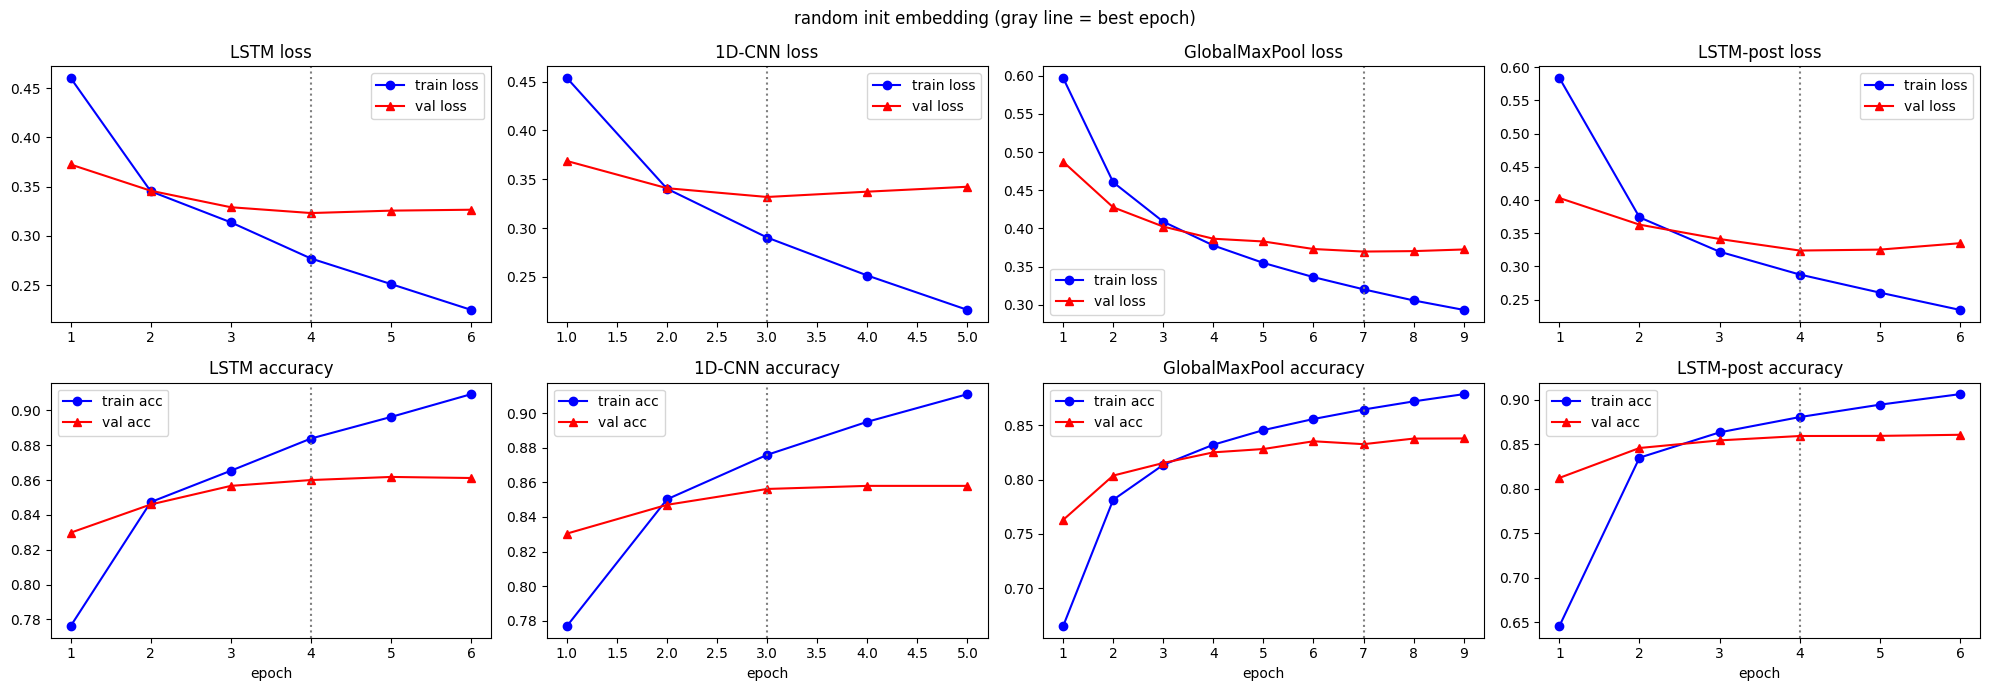

In [22]:
def plot_histories(hist_dict, title=''):
    fig, axes = plt.subplots(2, len(hist_dict), figsize=(5 * len(hist_dict), 7), squeeze=False)
    for col, (name, r) in enumerate(hist_dict.items()):
        h = r['history']; ep = range(1, len(h['train_loss']) + 1)
        axes[0, col].plot(ep, h['train_loss'], 'bo-', label='train loss')
        axes[0, col].plot(ep, h['val_loss'], 'r^-', label='val loss')
        axes[0, col].axvline(r['best_epoch'], color='gray', linestyle=':')
        axes[0, col].set_title(f'{name} loss'); axes[0, col].legend()
        axes[1, col].plot(ep, h['train_acc'], 'bo-', label='train acc')
        axes[1, col].plot(ep, h['val_acc'], 'r^-', label='val acc')
        axes[1, col].axvline(r['best_epoch'], color='gray', linestyle=':')
        axes[1, col].set_title(f'{name} accuracy'); axes[1, col].set_xlabel('epoch'); axes[1, col].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_histories({**results, 'LSTM-post': lstm_post}, 'random init embedding (gray line = best epoch)')

세 모델 모두 train loss는 계속 내려가는데, val loss는 LSTM 4 epoch, 1D-CNN 3 epoch, GlobalMaxPool 7 epoch에서 가장 낮고 그 뒤로 조금씩 다시 올라간다. 이후에는 train 정확도만 오르고 val 정확도는 거의 그대로라서 이 지점부터를 과적합으로 봤다. 그래서 val loss 기준 early stopping(patience 2)을 걸고, val loss가 가장 낮은 epoch(회색 점선)의 가중치로 되돌려서 썼다.

- LSTM과 1D-CNN은 val 정확도 86% 근처에서 비슷하게 수렴했고, CNN이 1 epoch 더 빨리 과적합이 시작됐다.
- GlobalMaxPool은 단어 순서를 쓰지 않는 모델이라 같은 epoch에서 train 정확도 자체가 다른 두 모델보다 낮고, val 정확도도 83%대에서 멈췄다. 과적합보다는 모델 표현력이 부족한 쪽으로 보인다.
- LSTM-post는 1 epoch val 정확도가 81.2%로 pre(83.0%)보다 느리게 출발했지만 4 epoch에서는 85.9%로 pre(86.0%)와 거의 같아졌다. 노드에서는 pre가 10% 이상 유리하다고 했는데, NSMC는 maxlen이 41로 짧아서 문장 뒤에 붙는 패딩이 IMDB(maxlen 580)만큼 길지 않기 때문인 것 같다.

In [23]:
# 모델과 epoch 선택은 위에서 val loss로 끝냈고, test는 여기서 모델마다 한 번씩만 평가한다.
loss_fn = nn.BCEWithLogitsLoss()
test_loader_post = DataLoader(TensorDataset(pad_sequences(X_test, maxlen, 'post'), torch.tensor(y_test, dtype=torch.float32)), batch_size=1024)
summary = []
for name, r in {**results, 'LSTM-post': lstm_post}.items():
    h = r['history']; b = r['best_epoch'] - 1
    _, test_acc = run_epoch(r['model'], test_loader_post if name == 'LSTM-post' else test_loader, loss_fn)
    summary.append((name, r['best_epoch'], h['train_acc'][b], h['val_acc'][b], test_acc))
print(f'{"model":<15}{"best ep":>8}{"train acc":>11}{"val acc":>9}{"test acc":>10}')
for row in summary:
    print(f'{row[0]:<15}{row[1]:>8}{row[2]:>11.4f}{row[3]:>9.4f}{row[4]:>10.4f}')

model           best ep  train acc  val acc  test acc
LSTM                  4     0.8839   0.8600    0.8570
1D-CNN                3     0.8759   0.8561    0.8510
GlobalMaxPool         7     0.8643   0.8325    0.8281
LSTM-post             4     0.8803   0.8590    0.8562


모델과 epoch는 val 기준으로만 골랐고, test는 각 모델에 한 번씩만 평가했다. LSTM이 85.70%로 가장 높았고 1D-CNN 85.10%, GlobalMaxPool 82.81% 순이다. val 순위와 test 순위가 같고 val과 test의 차이도 0.3에서 0.5%p 정도라서, val로 고른 결과가 test에서도 크게 흔들리지 않았다. LSTM과 1D-CNN은 루브릭 기준인 85%를 넘었다.

pre/post padding의 test 차이는 0.08%p로, test에서도 거의 차이가 없었다.

## 7) 학습된 Embedding 레이어 분석
---

In [24]:
# LSTM(랜덤 초기화)에서 학습된 임베딩을 word2vec 텍스트 형식으로 저장한 뒤 gensim으로 읽는다.
os.makedirs('/content/sentiment_classification/data', exist_ok=True)
my_vec_path = '/content/sentiment_classification/data/word2vec_nsmc_lstm.txt'
vectors = results['LSTM']['model'].embedding.weight.detach().cpu().numpy()
with open(my_vec_path, 'w') as f:
    f.write(f'{vocab_size - 4} {word_vector_dim}\n')
    for i in range(4, vocab_size):
        f.write(index_to_word[i] + ' ' + ' '.join(map(str, vectors[i])) + '\n')
my_vectors = KeyedVectors.load_word2vec_format(my_vec_path, binary=False)

def show_similar(word, topn=8):
    mine = [f'{w}({s:.2f})' for w, s in my_vectors.most_similar(word, topn=topn)] if word in my_vectors else ['사전에 없음']
    pre = [f'{w}({s:.2f})' for w, s in w2v.most_similar(word, topn=topn)] if word in w2v else ['사전에 없음']
    print(f'■ {word}')
    print('  자체학습 :', ', '.join(mine))
    print('  word2vec :', ', '.join(pre))

for word in ['재미', '최고', '감동', '지루', '쓰레기', '배우', '연기', '스토리']:
    show_similar(word)

■ 재미
  자체학습 : 모시(0.35), 특촬물(0.35), 관객(0.34), 평온(0.32), 기법(0.32), 라서(0.32), 시련(0.32), 두근거리(0.31)
  word2vec : 묘미(0.62), 취미(0.60), 흥미(0.59), 유머(0.59), 보람(0.57), 즐거움(0.56), 개그(0.56), 이야기(0.55)
■ 최고
  자체학습 : 설명(0.38), 남아도(0.35), 낙(0.35), 웨폰(0.33), 3500(0.33), 강우석(0.33), 상위(0.33), 사(0.32)
  word2vec : 역대(0.65), 최다(0.61), 최악(0.61), 최대(0.60), 최저(0.59), 정상급(0.59), 올해(0.58), 우수(0.57)
■ 감동
  자체학습 : 넘어가(0.37), 심은경(0.36), 넘길(0.35), 충만(0.35), 가만히(0.34), 냉소(0.33), 장국영(0.33), 삽입곡(0.32)
  word2vec : 감격(0.80), 감탄(0.73), 매혹(0.73), 매력(0.71), 감명(0.71), 웃음(0.70), 열정(0.69), 칭찬(0.68)
■ 지루
  자체학습 : 욕(0.36), 몰락(0.35), 짐작(0.35), 한숨(0.35), 류영화(0.34), 연쇄(0.33), 스티(0.33), 못생김(0.33)
  word2vec : 답답(0.84), 불쾌(0.84), 지저분(0.83), 조용(0.83), 피곤(0.82), 쓸쓸(0.81), 어색(0.81), 침울(0.81)
■ 쓰레기
  자체학습 : 에러(0.40), 잘라(0.36), 베트(0.35), 나와요(0.35), 인주(0.33), 고소영(0.33), 부재(0.32), 웩(0.32)
  word2vec : 폐수(0.77), 폐기물(0.76), 지하수(0.69), 식수(0.69), 더미(0.69), 분뇨(0.68), 소각장(0.68), 하수(0.68)
■ 배우
  자체학습 : 우익(0.38), 밋기(0.36), 엉성(0.35), 돋보이(0.34), 

자체 학습한 임베딩은 이웃 단어의 유사도가 0.3에서 0.4 정도로 낮고, '재미' 옆에 '모시', '특촬물', '최고' 옆에 '설명', '웨폰'처럼 의미 관계가 없는 단어들이 나왔다. 감성 분류 loss만으로 1만 단어 × 100차원을 4 epoch 학습한 것이라, 임베딩이 단어의 뜻보다는 긍정/부정을 가르는 데 필요한 정보만 담은 것으로 보인다. 노드에서 IMDB 임베딩으로 'love'를 찾았을 때와 같은 결과다.

word2vec_ko는 '재미 → 묘미, 흥미, 즐거움', '배우 → 영화배우, 여배우', '스토리 → 줄거리, 시나리오'처럼 뜻이 가까운 단어를 잘 찾는다. 다만 감성분석에 그대로 쓰기에는 걸리는 부분도 있었다.

- '최고'의 이웃에 '최악'이 들어 있다. word2vec은 주변 문맥이 비슷한 단어를 가깝게 두기 때문에 반대 감성의 단어도 가까이 올 수 있다.
- '쓰레기'의 이웃은 '폐수, 폐기물, 분뇨'로, 리뷰에서 욕으로 쓰는 뜻이 아니라 사전적인 뜻만 반영돼 있다. 리뷰가 아닌 일반 문서로 학습된 벡터라서 그런 것 같다.
- '지루'의 이웃은 '답답, 불쾌, 피곤'처럼 부정적인 단어끼리 잘 모여 있어서, 이런 단어에서는 도움이 될 것 같다.

## 8) 한국어 Word2Vec 임베딩 활용하여 성능 개선
---
- 한국어 Word2Vec은 /data 폴더 안에 있는 word2vec_ko.model을 활용하세요.
- 한국어 Word2Vec을 활용할 때는 `load_word2vec_format()` 형태가 아닌 `load()` 형태로 모델을 불러와주세요. 또한 모델을 활용할 때에는 아래 예시와 같이 `.wv`를 붙여서 활용합니다. 좀더 자세한 활용법에 대해선 다음 링크들을 참조해주세요. [참고 링크1](https://radimrehurek.com/gensim/auto_examples/tutorials/run_word2vec.html#storing-and-loading-models), [참고 링크2](https://radimrehurek.com/gensim/models/keyedvectors.html)



```
# 예시 코드
from gensim.models.keyedvectors import Word2VecKeyedVectors
word_vectors = Word2VecKeyedVectors.load(word2vec_file_path)
vector = word_vectors.wv[‘끝’]
```



In [27]:
# 사전 단어마다 word2vec_ko 벡터를 복사한다. 없는 단어는 word2vec 벡터의 분포에 맞춘 랜덤값으로 둔다.
rng = np.random.default_rng(SEED)
embedding_matrix = rng.normal(0, w2v.vectors.std(), size=(vocab_size, word_vector_dim)).astype(np.float32)
embedding_matrix[0] = 0  # <PAD>
found = 0
for i in range(4, vocab_size):
    if index_to_word[i] in w2v:
        embedding_matrix[i] = w2v[index_to_word[i]]
        found += 1
print(f'사전 {vocab_size - 4}개 단어 중 word2vec_ko에 있는 단어: {found}개 ({found / (vocab_size - 4):.2%})')
missing = [index_to_word[i] for i in range(4, vocab_size) if index_to_word[i] not in w2v]
print('word2vec에 없는 단어 예 (빈도순):', missing[:20])

사전 9996개 단어 중 word2vec_ko에 있는 단어: 9435개 (94.39%)
word2vec에 없는 단어 예 (빈도순): ['ㅠㅠ', '....', 'ㅜㅜ', 'ㅋㅋㅋㅋ', '강추', '~~~', ';;;', '.....', 'ㅉㅉ', '아까움', '-_-', '네여', '왠만', '별루', 'ㅠㅠㅠ', 'ㅋㅋㅋㅋㅋ', '봣는데', '......', '낚였', '~~~~']


In [28]:
# 위 LSTM과 구조·하이퍼파라미터를 똑같이 두고 임베딩 초기값만 word2vec_ko로 바꾼다 (임베딩도 같이 학습).
set_seed(); results['LSTM+word2vec'] = train_model('LSTM+word2vec', LSTMClassifier(vocab_size, word_vector_dim, embedding_matrix=embedding_matrix), train_loader, val_loader)

[LSTM+word2vec] epoch  1 | train loss 0.4435 acc 0.7892 | val loss 0.3549 acc 0.8430
[LSTM+word2vec] epoch  2 | train loss 0.3274 acc 0.8579 | val loss 0.3222 acc 0.8612
[LSTM+word2vec] epoch  3 | train loss 0.2872 acc 0.8787 | val loss 0.3109 acc 0.8658
[LSTM+word2vec] epoch  4 | train loss 0.2609 acc 0.8910 | val loss 0.3108 acc 0.8686
[LSTM+word2vec] epoch  5 | train loss 0.2367 acc 0.9026 | val loss 0.3173 acc 0.8691
[LSTM+word2vec] epoch  6 | train loss 0.2142 acc 0.9137 | val loss 0.3198 acc 0.8705
[LSTM+word2vec] best epoch 4, val acc 0.8686, 26s


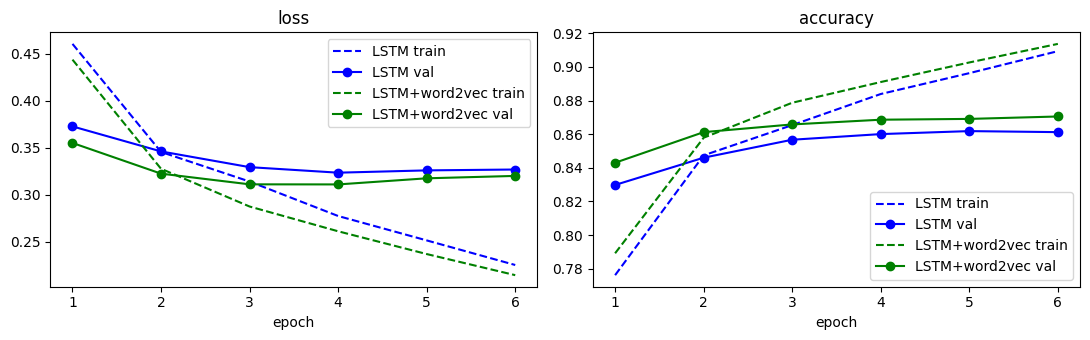

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, style in [('LSTM', 'b'), ('LSTM+word2vec', 'g')]:
    h = results[name]['history']; ep = range(1, len(h['val_loss']) + 1)
    axes[0].plot(ep, h['train_loss'], style + '--', label=f'{name} train')
    axes[0].plot(ep, h['val_loss'], style + '-o', label=f'{name} val')
    axes[1].plot(ep, h['train_acc'], style + '--', label=f'{name} train')
    axes[1].plot(ep, h['val_acc'], style + '-o', label=f'{name} val')
axes[0].set_title('loss'); axes[1].set_title('accuracy')
for ax in axes: ax.set_xlabel('epoch'); ax.legend()
plt.tight_layout(); plt.show()

사전 단어 9,996개 중 94.4%가 word2vec_ko에 있었다. 없는 단어는 'ㅠㅠ', 'ㅋㅋㅋㅋ', '강추', '별루', '-_-'처럼 리뷰에서 감성을 강하게 드러내는 이모티콘과 줄임말이 많았고, 이 단어들은 랜덤 초기값에서 학습해야 했다.

같은 LSTM 구조에서 임베딩 초기값만 바꿨더니 1 epoch부터 val 정확도가 84.3%로 랜덤 초기화(83.0%)보다 높게 시작했고, val loss도 모든 epoch에서 더 낮았다. 가장 낮은 val loss는 0.3108로 랜덤 초기화(0.3233)보다 낮다. train 정확도는 계속 오르고 val은 87% 근처에서 멈추는 과적합 패턴은 두 모델이 같아서, 사전학습 임베딩이 과적합을 막아 줬다기보다는 출발점을 좋게 만들어 준 것으로 보인다.

셀 43의 출력 부분을 고쳐서 43, 44를 다시 실행했을 때, seed가 같은데도 best epoch가 3에서 4로, val 정확도가 86.80%에서 86.86%로 조금 바뀌었다. GPU의 LSTM 연산이 완전히 결정적이지 않아서 생기는 차이라, 모델끼리 비교할 때 0.1%p 단위 차이는 의미 있게 보지 않았다.

In [30]:
r = results['LSTM+word2vec']; h = r['history']; b = r['best_epoch'] - 1
test_loss, test_acc = run_epoch(r['model'], test_loader, loss_fn)
summary.append(('LSTM+word2vec', r['best_epoch'], h['train_acc'][b], h['val_acc'][b], test_acc))
print(f'{"model":<15}{"best ep":>8}{"train acc":>11}{"val acc":>9}{"test acc":>10}')
for row in summary:
    print(f'{row[0]:<15}{row[1]:>8}{row[2]:>11.4f}{row[3]:>9.4f}{row[4]:>10.4f}')

# 학습이 끝난 임베딩에서 같은 단어들의 이웃이 어떻게 바뀌었는지 확인
tuned = r['model'].embedding.weight.detach().cpu().numpy()
tuned_vectors = KeyedVectors(vector_size=word_vector_dim)
tuned_vectors.add_vectors([index_to_word[i] for i in range(4, vocab_size)], tuned[4:])
for word in ['재미', '최고', '지루']:
    print(word, '→', [w for w, _ in tuned_vectors.most_similar(word, topn=8)])

model           best ep  train acc  val acc  test acc
LSTM                  4     0.8839   0.8600    0.8570
1D-CNN                3     0.8759   0.8561    0.8510
GlobalMaxPool         7     0.8643   0.8325    0.8281
LSTM-post             4     0.8803   0.8590    0.8562
LSTM+word2vec         4     0.8910   0.8686    0.8628
재미 → ['묘미', '취미', '흥미', '유머', '보람', '즐거움', '개그', '공감']
최고 → ['역대', '최대', '올해', '우수', '최저', '최초', '최악', '최강']
지루 → ['답답', '불쾌', '피곤', '어색', '지저분', '끔찍', '따분', '멍청']


최종 test 정확도는 word2vec_ko로 초기화한 LSTM이 86.28%로 가장 높았고, 같은 구조의 랜덤 초기화 LSTM(85.70%)보다 0.58%p 올랐다. 루브릭 기준인 85%는 LSTM, 1D-CNN, LSTM-post, LSTM+word2vec 네 모델이 넘었다. 노드에서는 Word2Vec을 쓰면 5% 이상 오른다고 했지만, 여기서는 랜덤 초기화 모델도 이미 85%를 넘고 학습 데이터가 13만 개로 충분해서 개선 폭이 작았던 것 같다.

학습이 끝난 뒤에도 '재미', '지루'의 이웃은 뜻이 비슷한 단어로 유지됐고 '최고'의 이웃에는 여전히 '최악'이 있다. 4 epoch 학습으로는 사전학습 벡터의 구조가 거의 그대로 남는다는 뜻이고, 반대 감성 단어를 떨어뜨리려면 임베딩 학습률을 따로 주거나 더 오래 학습해야 할 것 같다.

test는 각 모델에 한 번씩만 평가했고, 그 결과를 보고 모델이나 하이퍼파라미터를 다시 고치지 않았다. 다만 같은 test로 여러 모델을 비교했기 때문에 이 표에서 test가 가장 높은 모델을 고르는 것은 test를 선택에 쓰는 셈이 된다. 최종 모델을 하나 고른다면 val 기준으로도 가장 높은 LSTM+word2vec이 맞다.

## 회고 (KPT)

### Keep
- 모델과 epoch는 val loss로만 고르고, test는 모델마다 한 번씩만 평가했습니다. val과 test 순위가 같았고 차이도 0.3에서 0.5%p 정도여서 이렇게 고른 결과를 믿을 수 있었습니다.
- 에러 없이 돌아가는 원본 코드도 그대로 쓰지 않고 사전을 직접 확인했습니다. 이 과정에서 `load_data`의 특수 토큰이 빈 문자열이라 인덱스가 겹치는 문제를 찾았습니다.
- 노드에서 나온 내용(pre padding이 10% 이상 유리)을 NSMC로 직접 비교해 봤고, 문장이 짧은 데이터에서는 차이가 거의 없다는 것을 확인했습니다.
- word2vec 실험은 LSTM 구조와 하이퍼파라미터를 그대로 두고 임베딩 초기값만 바꿔서, 바뀐 조건이 하나만 있도록 비교했습니다.

### Problem
- 교재의 MeCab 설치 방법이 Colab(Python 3.13)에서 동작하지 않아 설치 단계에서 시간이 걸렸습니다.
- 모델마다 seed 하나로 한 번씩만 학습해서, 0.5%p 안쪽의 차이(LSTM과 1D-CNN, pre와 post)는 우연일 수 있습니다. 같은 seed로 다시 실행했을 때도 val 정확도가 0.06%p 달라졌습니다.
- word2vec_ko에 없는 이모티콘과 줄임말(ㅋㅋ, ㅠㅠ, 강추 등)은 감성 신호가 강한데도 랜덤 초기값에서 시작했습니다.
- word2vec_ko에서 '최고'와 '최악'이 가깝게 나오는 것처럼, 사전학습 임베딩이 반대 감성의 단어를 구분하지 못하는 경우가 있었습니다.
- word2vec_ko 파일이 LMS 실습환경의 /data에만 있어서, 그 환경에서 KeyedVectors만 저장해 Colab으로 옮겼습니다. 벡터 값은 같지만 실행 환경이 두 곳으로 나뉘었습니다.

### Try
- seed를 3개 이상으로 바꿔 반복하고, 평균과 편차로 모델을 비교해 보고 싶습니다.
- 리뷰 데이터로 Word2Vec을 추가 학습하거나 이모티콘과 줄임말을 따로 처리해서, 사전학습 임베딩에 없는 감성 단어를 보완해 보고 싶습니다.
- 양방향 LSTM, 임베딩을 처음 몇 epoch 동안 고정했다가 푸는 방식, 사전 크기(num_words) 변경을 val 기준으로 비교해 보고 싶습니다.